In [2]:
import numpy as np
import librosa
import pandas as pd
import os
import scipy.stats
from scipy.stats import skew, kurtosis, entropy

import sys
sys.path.append(os.path.abspath("../src"))

from wavelet_utils import wavelet_denoise



# --- Feature extractors ---
def extract_features(x, sr):
    feats = {}
    feats["mean"] = np.mean(x)
    feats["std"] = np.std(x)
    feats["energy"] = np.sum(x**2)
    feats['IQR'] = np.percentile(x, 75) - np.percentile(x, 25)
    #feats["zcr"] = np.mean(librosa.feature.zero_crossing_rate(x)[0])
    mfccs = librosa.feature.mfcc(y=x, sr=sr, n_mfcc=5)
    for i in range(mfccs.shape[0]):
        feats[f"mfcc{i+1}"] = np.mean(mfccs[i])
    return feats

# --- Dataset paths ---
classes = ["AS","MR", "MS","MVP", "Normal"]
data = []

for label in classes:
    path = f"../data/train/{label}"
    files = [f for f in os.listdir(path) if f.endswith(".wav")]
    for f in files:
        x, sr = librosa.load(os.path.join(path,f), sr=2000)
        x_dn = wavelet_denoise(x)
        feats = extract_features(x_dn, sr)
        feats["label"] = label
        data.append(feats)

df = pd.DataFrame(data)
print(df.head())
df.to_csv("5Classesfeatures.csv", index=False)


D:\Installations\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


       mean       std      energy       IQR       mfcc1       mfcc2  \
0  0.001399  0.232176  281.073517  0.039723 -108.591522  174.681549   
1  0.000077  0.232448  281.724182  0.040627 -109.456024  172.415894   
2  0.001254  0.230958  278.559204  0.040736 -113.462799  173.126953   
3 -0.000611  0.231486  279.612762  0.041888 -110.329857  173.171982   
4 -0.000573  0.226115  268.320282  0.041333 -113.135788  173.954849   

       mfcc3     mfcc4      mfcc5 label  
0  32.392426  6.963603 -23.962652    AS  
1  25.369661  6.790050 -21.353704    AS  
2  29.444977  9.655674 -27.248644    AS  
3  29.359678  5.562475 -26.354345    AS  
4  34.665356  5.382925 -24.963335    AS  


In [3]:
normal_signal, sr = librosa.load("../data/train/Normal/New_N_003.wav", sr=2000)
abnormal_signal_AS, sr = librosa.load("../data/train/AS/New_AS_002.wav", sr=2000)
abnormal_signal_MS, sr = librosa.load("../data/train/MS/New_MS_002.wav", sr=2000)
abnormal_signal_MR, sr = librosa.load("../data/train/MR/New_MR_002.wav", sr=2000)
abnormal_signal_MVP, sr = librosa.load("../data/train/MVP/New_MVP_002.wav", sr=2000)

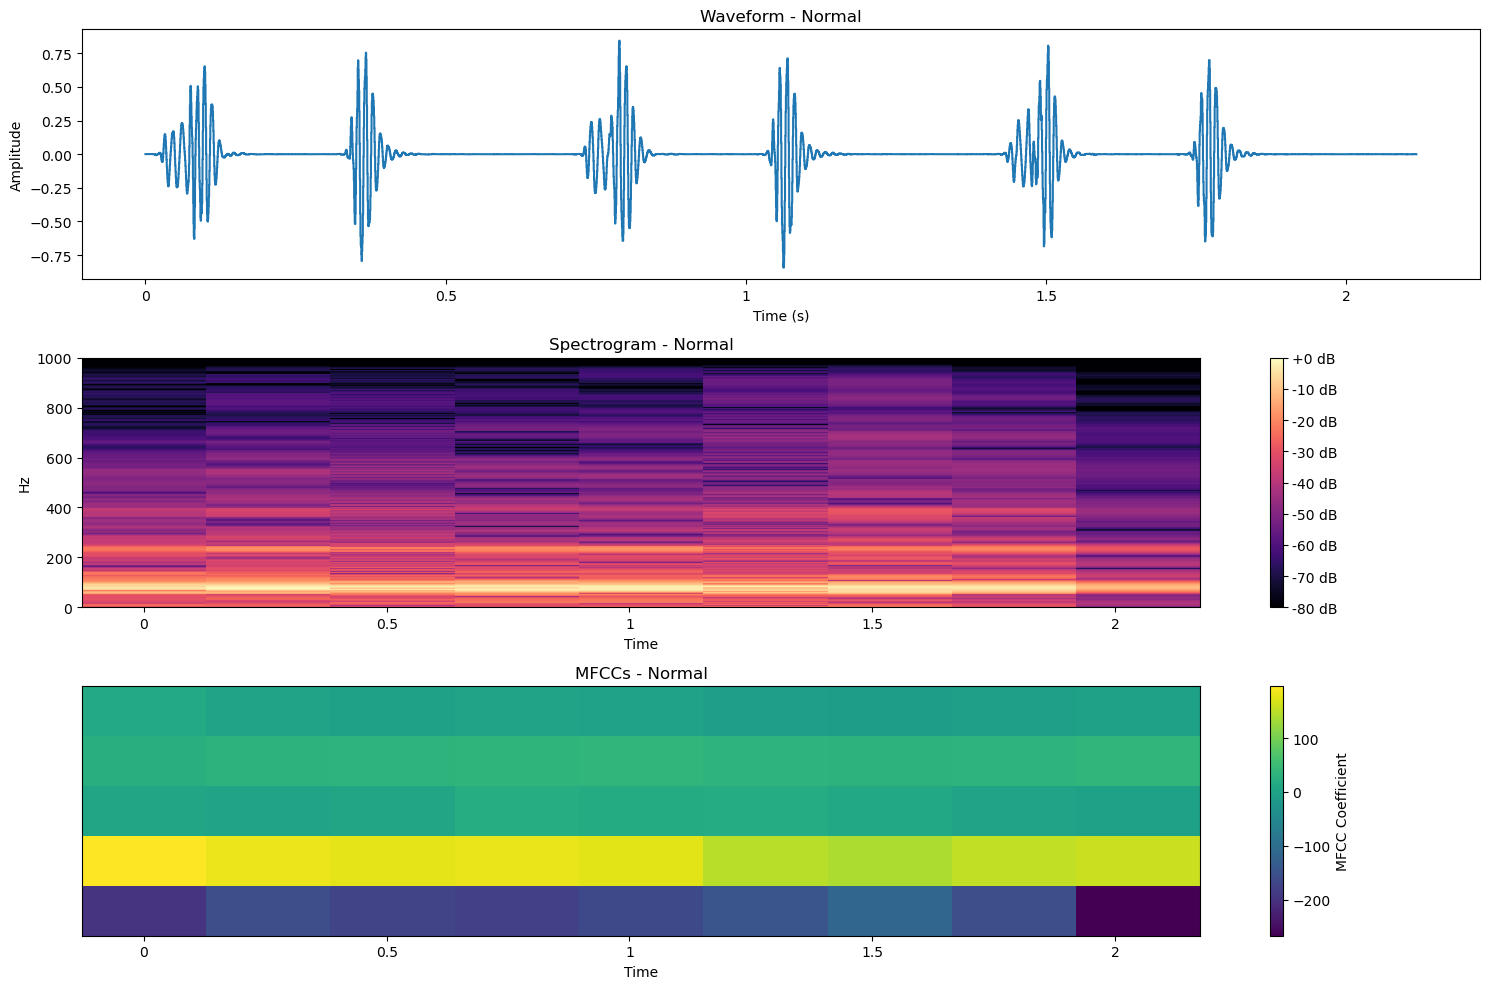

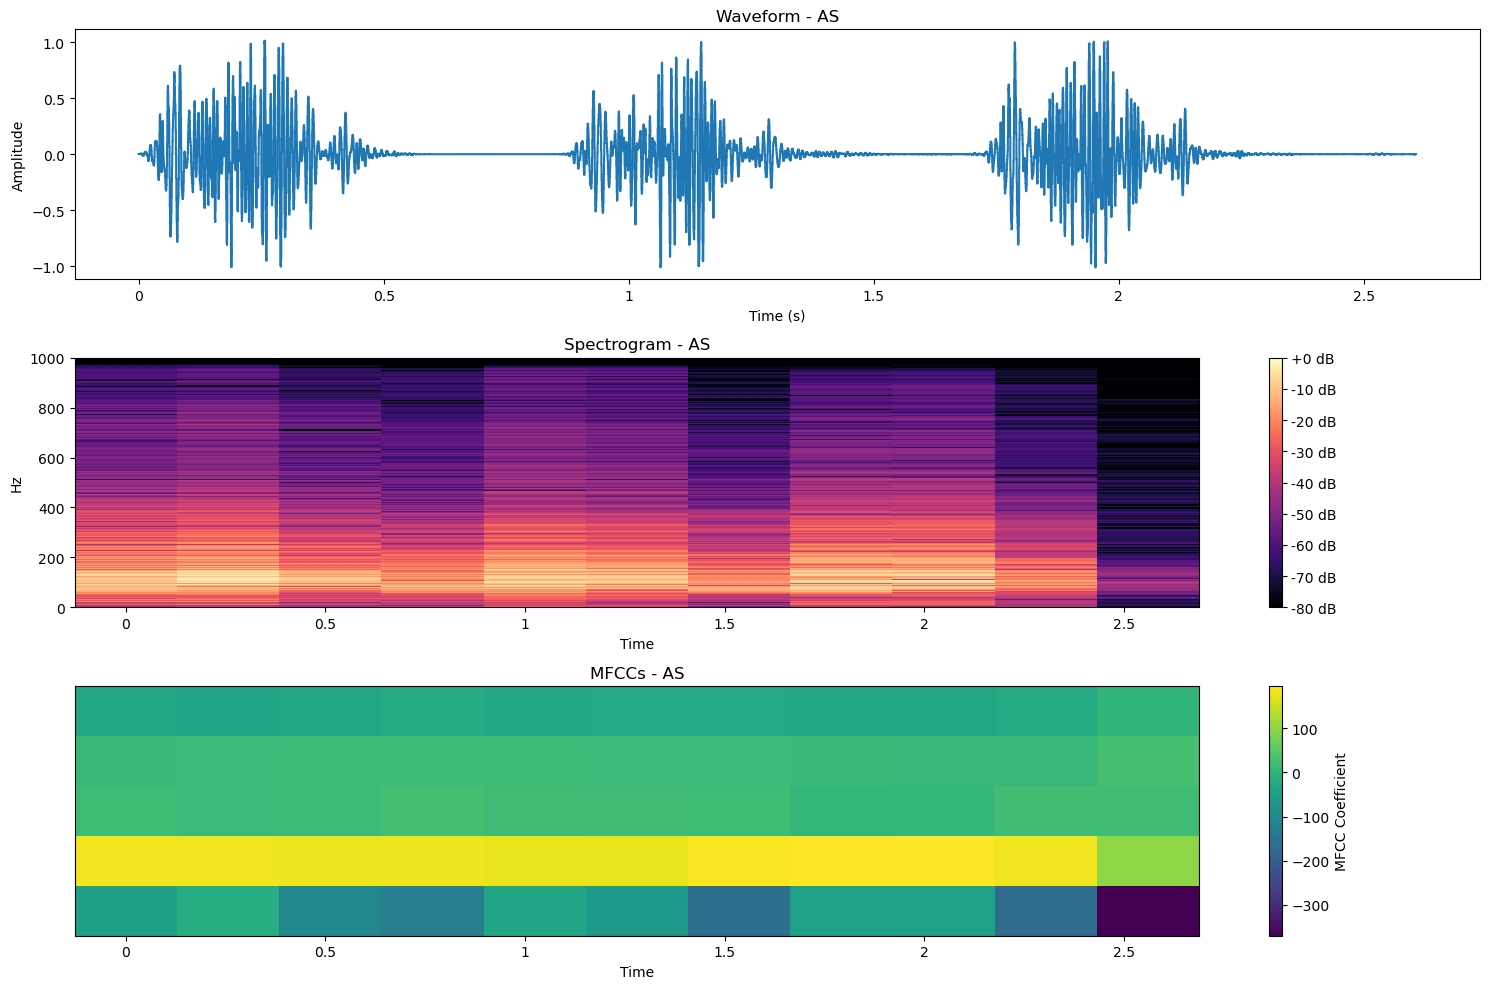

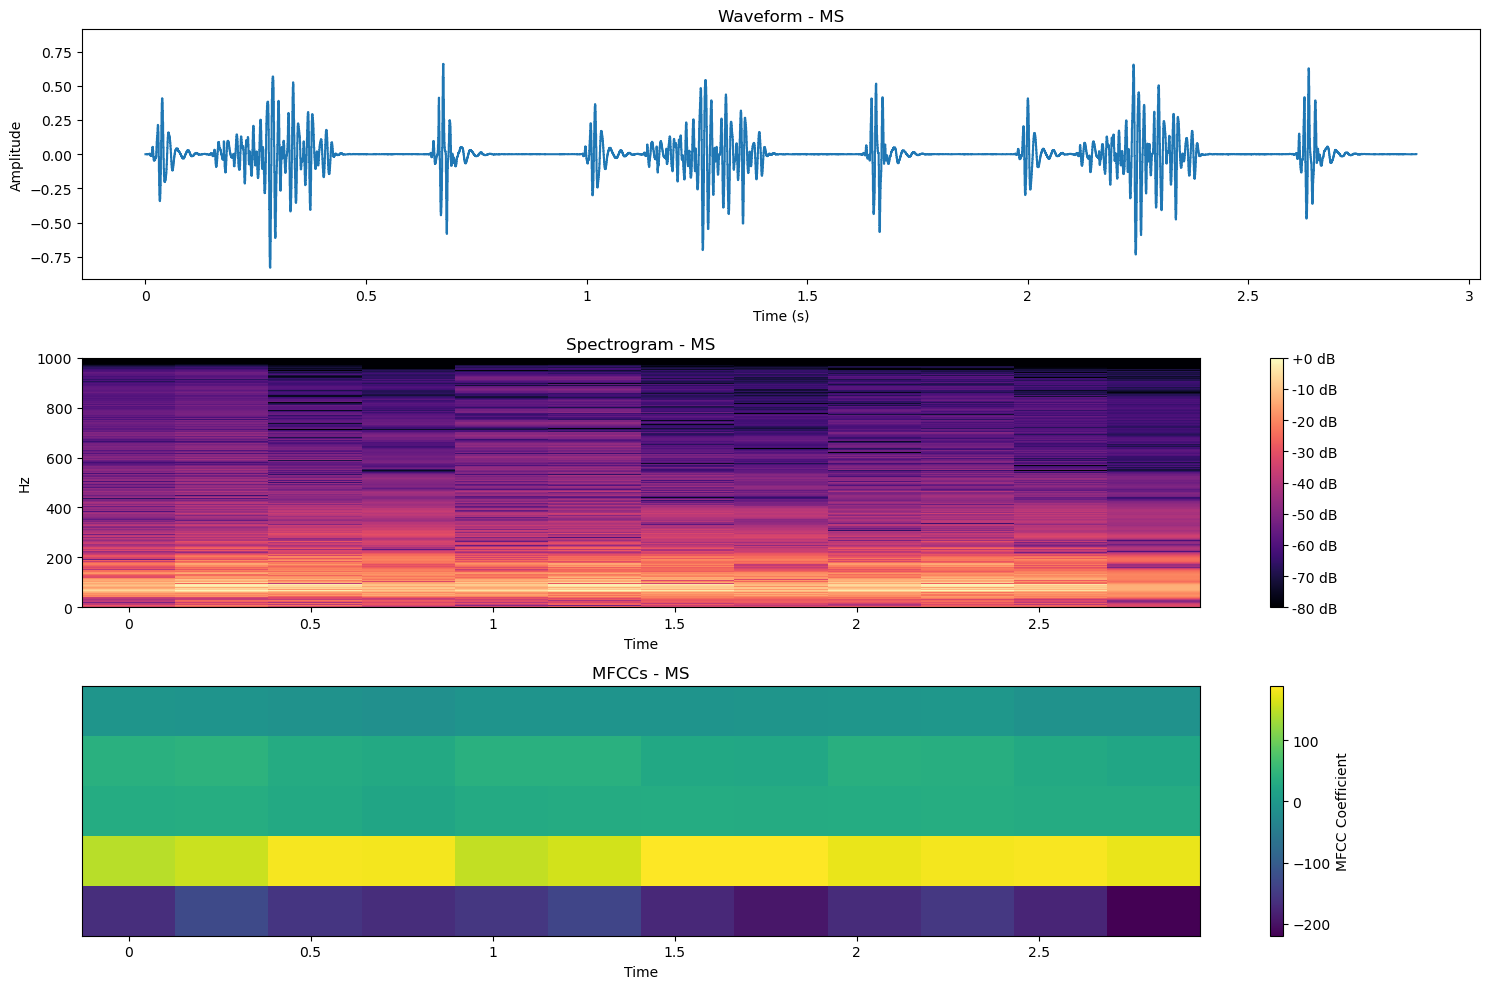

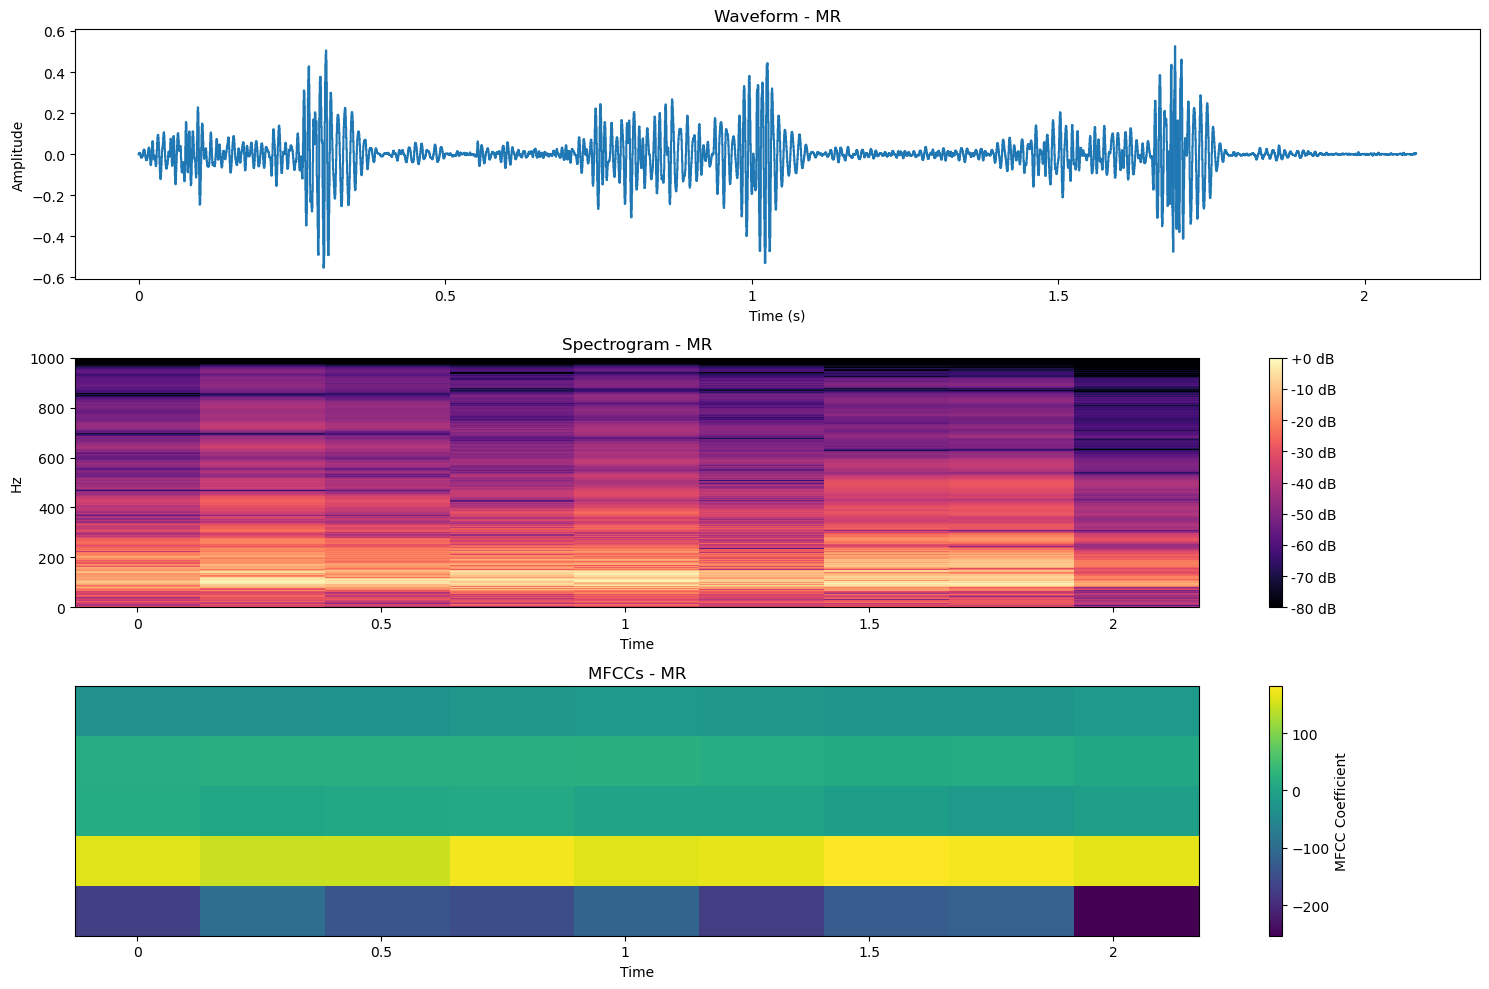

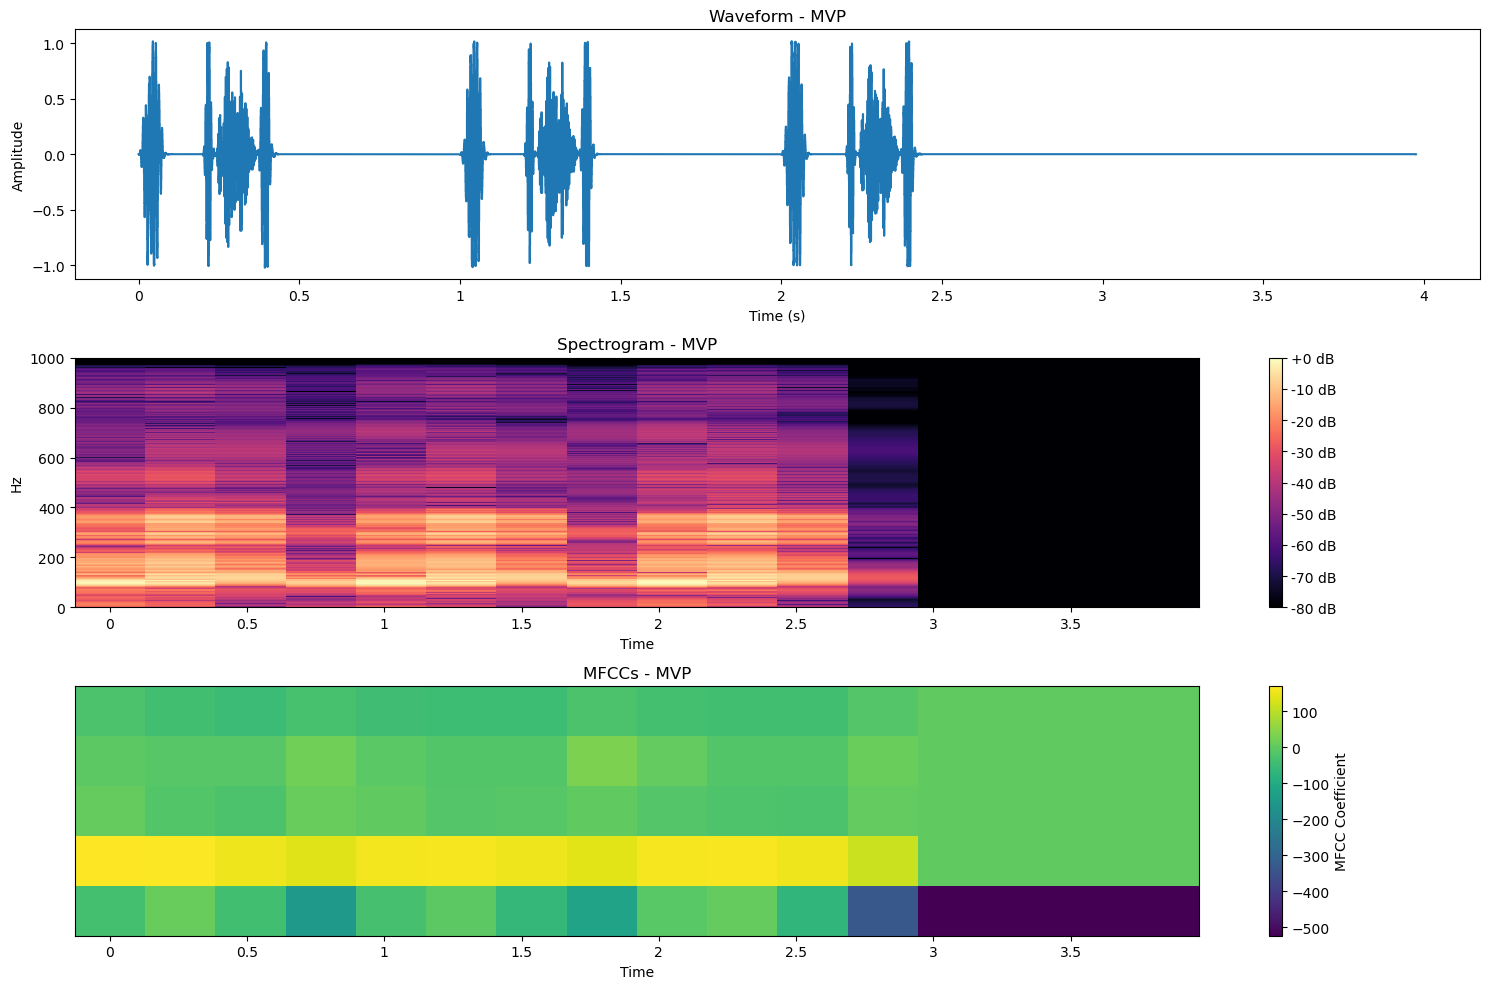

In [3]:
import matplotlib.pyplot as plt
import librosa, librosa.display
import numpy as np

signals = {
    "Normal": normal_signal,
    "AS": abnormal_signal_AS,
    "MS": abnormal_signal_MS,
    "MR": abnormal_signal_MR,
    "MVP": abnormal_signal_MVP
}

for label, sig in signals.items():
    plt.figure(figsize=(15, 10))
    
    # 1) Waveform
    plt.subplot(3, 1, 1)
    librosa.display.waveshow(sig, sr=sr)
    plt.title(f"Waveform - {label}")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    
    # 2) Spectrogram (STFT)
    plt.subplot(3, 1, 2)
    S = np.abs(librosa.stft(sig))
    S_db = librosa.amplitude_to_db(S, ref=np.max)
    librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz", cmap="magma")
    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Spectrogram - {label}")
    
    # 3) MFCC Spectrogram
    plt.subplot(3, 1, 3)
    mfccs = librosa.feature.mfcc(y=sig, sr=sr, n_mfcc=5)
    librosa.display.specshow(mfccs, sr=sr, x_axis="time", cmap="viridis")
    plt.colorbar(label="MFCC Coefficient")
    plt.title(f"MFCCs - {label}")
    
    plt.tight_layout()
    plt.show()
